<a href="https://colab.research.google.com/github/Jucksun/gsp-csice-research/blob/main/PracticeBlindDeconv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pygsp

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pygsp as pg

# Minnesota road network graph N = 2642
G = pg.graphs.Minnesota()
N = G.N

#  Graph Laplacian and U
S = G.L.toarray()
lam, U = np.linalg.eigh(S)

#  signals
M = 2000
rng = np.random.default_rng(42)

#GFT and C_hat_x
rho = 0.25
C_hat_x = (1 - rho) * np.eye(N) + rho * np.ones((N, N))

#  signals in GFT
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M).T
X = U @ X_hat


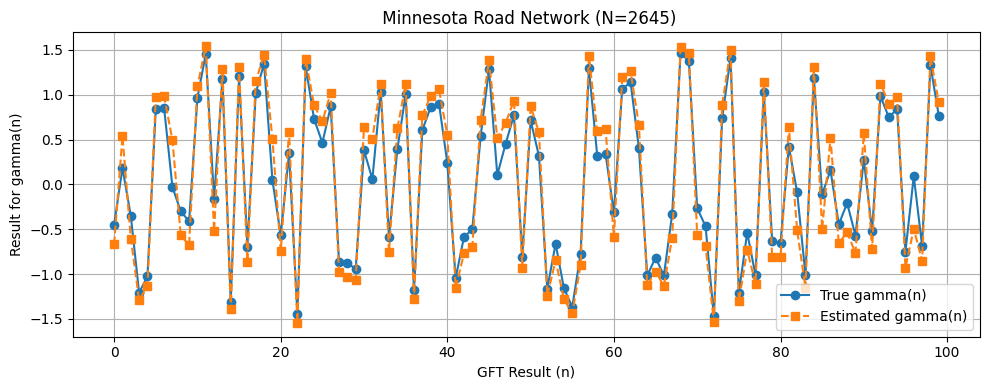

In [ ]:
# gamma_true = rng.choice([-1, 1], size=N) * (1 + rng.uniform(-0.5, 0.5, size=N))
gamma_true = rng.uniform(-1.5, 1.5, size=N)
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M).T  #clean
Y_hat = np.diag(gamma_true) @ X_hat + 0.5 * rng.standard_normal((N, M)) #chud

C_hat_y = (Y_hat @ Y_hat.T / M)

gamma_abs = np.sqrt(np.maximum(0, np.diag(C_hat_y) / np.diag(C_hat_x)))

##############################################################################
# This is supposed to be like the signs, I think it didnt work...


gamma_sign = np.ones(N)
gamma_sign[1:] = np.sign(C_hat_y[1:, 0] / C_hat_x[1:, 0])

gamma_est = gamma_abs * gamma_sign

if np.dot(gamma_est, gamma_true) < 0:
    gamma_est = -gamma_est

##############################################################################
# This is like, the final part i think.

X_reconstructed = U @ (np.diag(1.0 / gamma_est) @ Y_hat)


plt.figure(figsize=(10, 4))
plt.plot(gamma_true[:100], "o-", label="True gamma(n)")
plt.plot(gamma_est[:100], "s--", label="Estimated gamma(n)")
plt.title(f" Minnesota Road Network (N=2645)")
plt.xlabel("GFT Result (n)")
plt.ylabel("Result for gamma(n)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()